# Lab 05: The Dark Companion, Two Years Later

**ASTR 457, Fall 2026, posted Sat Oct 3, due Fri Oct 9 by Noon (extended) (fork → PR, as always)**

*Why this lab: every orbit in the literature, from Gaia's black-hole binaries to the planets David Charbonneau talked about on Tuesday, is a posterior distribution over six or seven parameters that nobody can write down in closed form. Sampling it, knowing when the sampler has actually converged, and turning the samples into a number with an honest error bar is the core professional skill of modern astrophysics, and the place where confident, fluent, wrong analyses are most common.*

On Day 1 you watched a star's radial velocity drift over ten nights and inferred an unseen companion from
the slope alone. This is that programme, two and a half years on. Every one of you has your own star:
`data/<your netid>.csv`, with columns `t_days` (time of each spectrum, from the first epoch), `rv_kms`
(the measured radial velocity) and `sigma_rv_kms` (the pipeline's per-epoch uncertainty). The star was
observed in three observing seasons over about 900 days, 28 to 44 epochs in all. It is a **single-lined
spectroscopic binary**: you see one star's lines, the companion contributes no light, and the visible star
follows a Keplerian orbit,

$$v_r(t) = \gamma + K\left[\cos\big(\nu(t) + \omega\big) + e\cos\omega\right],$$

with period $P$, semi-amplitude $K$, eccentricity $e$, argument of periastron $\omega$, a time of periastron
$T_p$, systemic velocity $\gamma$, and $\nu(t)$ the true anomaly (the angle around the orbit, which you get
from Kepler's equation; a function is provided). What you are really after is the **mass function**

$$f(M) = \frac{P K^3 (1 - e^2)^{3/2}}{2\pi G} = \frac{M_2^3 \sin^3 i}{(M_1 + M_2)^2},$$

a lower limit on the companion's mass, in solar masses. If it comes out above about $3\,M_\odot$ for a
Sun-like primary, you have a black hole candidate, the way Gaia BH1 was found (El-Badry et al. 2023, the Sep 8
colloquium). In the units of your file, $f(M) = 1.0361\times10^{-7}\,(1-e^2)^{3/2} K^3 P$ with $K$ in km/s
and $P$ in days.

I know your true $P$, $K$, $e$ and $f(M)$. You don't, your classmates' stars are different, and so is the
sampling. **One more thing I know and you don't: the quoted `sigma_rv_kms` is not the whole error.** Real
radial velocities carry an extra scatter, called jitter, from the star's own surface and from template
mismatch, and it is not in the pipeline number.

**How this is graded.** As always, on whether your answers are *right* and your uncertainties are *honest*:
your reported $P$, $K$, $e$ and $f(M)$ are compared to your truth in units of your own reported uncertainty.
Anti-sandbagging cap: your $\sigma_K$ may not exceed $3\times$ a reference posterior width I compute for your
dataset. Padded error bars lose points like overconfident ones.

**AI policy reminder.** Use whatever tools you like, including AI assistants, and document it in Part 4. You
may be selected to defend this lab orally; the defense is easy if you did the work.

Weights: Part 1 15%, Part 2 40%, Part 3 35%, Part 4 10%.


In [4]:
import numpy as np
import matplotlib.pyplot as plt
import emcee
import corner
from scipy.optimize import minimize
from astropy.timeseries import LombScargle

# For me: 
import pandas as pd 

NETID = 'anuvacg2'   # <-- set this
d = np.genfromtxt(f'data/{NETID}.csv', delimiter=',', names=True)
t, rv, sig = d['t_days'], d['rv_kms'], d['sigma_rv_kms']

# Being nosy
df = pd.DataFrame( {"td": t, "rv": rv, "sig": sig} )
print(df)

print(f"{t.size} epochs over {t.max() - t.min():.0f} days; median quoted error {np.median(sig):.2f} km/s")

def kepler_rv(t, P, K, e, omega, Tp, gamma):
    """Radial velocity of the visible star in a Keplerian orbit.
    P period [d], K semi-amplitude [km/s], e eccentricity, omega argument of periastron [rad],
    Tp a time of periastron [d], gamma systemic velocity [km/s]. Solves Kepler's equation by Newton iteration."""
    M = 2. * np.pi * ((t - Tp) / P % 1.0)            # mean anomaly
    E = M.copy()                                     # eccentric anomaly
    for _ in range(30):
        E = E - (E - e * np.sin(E) - M) / (1. - e * np.cos(E))
    nu = 2. * np.arctan2(np.sqrt(1. + e) * np.sin(E / 2.), np.sqrt(1. - e) * np.cos(E / 2.))   # true anomaly
    return gamma + K * (np.cos(nu + omega) + e * np.cos(omega))

def mass_function(P, K, e):
    """f(M) in solar masses, for P in days and K in km/s."""
    return 1.0361e-7 * (1. - e**2)**1.5 * K**3 * P

         td          rv       sig
0    27.286  -82.615619  2.304429
1    28.630  -87.233170  2.562884
2    50.790 -109.870270  1.120669
3    74.335    8.710415  2.064519
4   102.985   29.530486  2.752989
5   106.312   22.805809  1.670290
6   129.076   17.010294  2.284298
7   167.430    5.229414  2.755897
8   175.825   -1.702528  2.201224
9   202.010   -1.501070  1.338047
10  380.711   22.776948  2.268891
11  380.991   27.410769  1.000995
12  387.837   19.322079  2.404614
13  406.156   13.064663  1.919113
14  425.458    4.118524  2.583020
15  439.164   -3.409188  2.374004
16  445.976   -7.563960  1.782366
17  479.575  -33.046674  2.066655
18  491.653  -43.130472  2.106805
19  521.096 -112.511182  2.517820
20  702.520  -19.067867  2.729249
21  736.605  -51.394063  1.326909
22  768.882 -128.665427  2.671210
23  787.964  -43.947524  2.267323
24  798.275    2.378420  1.442040
25  802.711   10.945922  1.333947
26  836.118   23.968814  2.699684
27  846.089   22.212773  1.511220
28  862.627   

## Part 1: Look first, then find the period (15%)

Plot the radial velocities against time with their error bars. Then find candidate orbital periods with a
Lomb-Scargle periodogram of the velocities (`astropy.timeseries.LombScargle`, Day 7's periodogram, formally
taught on Oct 20/22; for now it is a tool that ranks periods). Plot the periodogram. Then, for the best two or
three candidate periods, phase-fold the data and look.

Answer, in a few sentences: how many candidate periods are plausible from the periodogram alone, and why does
a Lomb-Scargle periodogram (which fits a *sinusoid*) not settle the question for an eccentric orbit? What
feature of the sampling (look at the gaps) produces the other peaks?


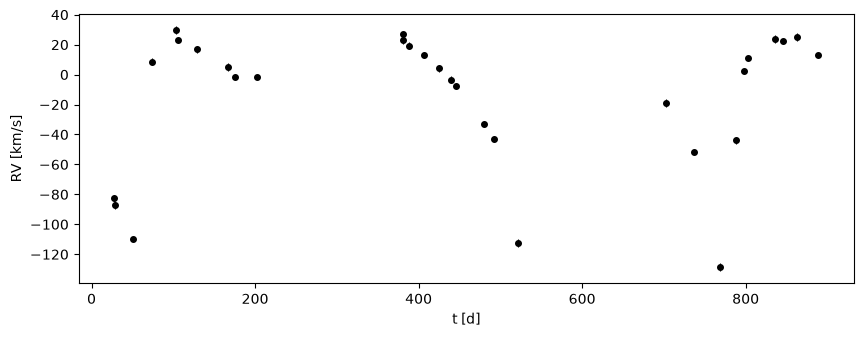

candidate periods [d]: [233.9 669.9   5.4]


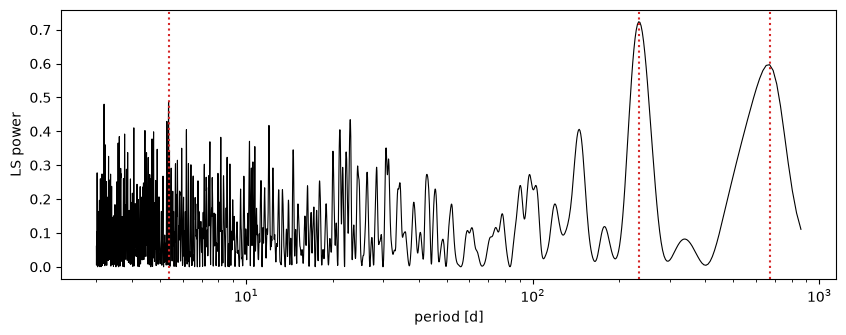

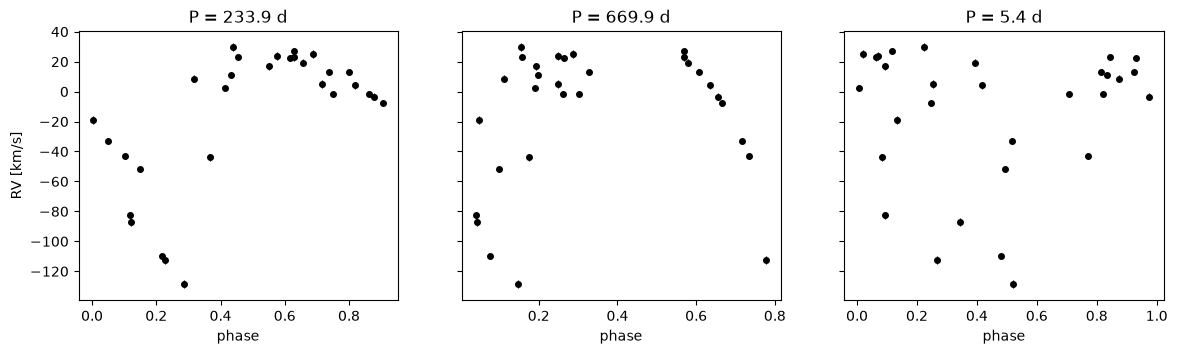

In [5]:
from scipy.signal import find_peaks

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.errorbar(t, rv, sig, fmt='o', ms=4, color='k', elinewidth=0.8)
ax.set_xlabel('t [d]'); ax.set_ylabel('RV [km/s]')
plt.show()

# Lomb-Scargle 
baseline = t.max() - t.min()
freq = np.linspace(1 / baseline, 1 / 3.0, 8000)
power = LombScargle(t, rv, sig).power(freq)
period = 1 / freq

pk, _ = find_peaks(power)
order = pk[np.argsort(power[pk])[::-1]]
cands = []
for i in order:
    if all(abs(period[i] / c - 1) > 0.05 for c in cands):
        cands.append(period[i])
    if len(cands) == 3:
        break
print("candidate periods [d]:", np.round(cands, 1))

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.semilogx(period, power, 'k', lw=0.8)
for c in cands:
    ax.axvline(c, color='C3', ls=':')
ax.set_xlabel('period [d]'); ax.set_ylabel('LS power')
plt.show()

fig, axs = plt.subplots(1, 3, figsize=(14, 3.5), sharey=True)
for ax, P0 in zip(axs, cands):
    ax.errorbar((t % P0) / P0, rv, sig, fmt='o', ms=4, color='k', elinewidth=0.8)
    ax.set_title(f'P = {P0:.1f} d'); ax.set_xlabel('phase')
axs[0].set_ylabel('RV [km/s]')
plt.show()

**ANSWER (a few sentences):**

The periodagram indicates 2 plausible peaks at 233.9d and 669.9d. The 5.4 d peak is just one of many comparable spikes at short periods, and it folds to scatter. The 233.9 d fold is single-valued with a sharp periastron dip, while 669.9 d is double-valued, so 233.9 d is the likely orbit. Lomb-Scargle is meant to fit sinusoidal waves that would be caused by perfectly circular orbits, so it cannot accurately describe an elliptical, eccentric orbit. 

## Part 2: Sample the posterior (40%)

Fit the six orbital parameters **plus a jitter term** $s$ with `emcee`. The likelihood for epoch $i$ is
Gaussian with variance $\sigma_i^2 + s^2$; write it out (including the $\log$ of the variance, which is not a
constant once $s$ is a parameter). You will need to:

1. **Write the log-likelihood, log-prior and log-posterior.** State every prior and justify it in one line
   each. Two traps: $\omega$ and $T_p$ are periodic ($T_p$ is only defined modulo $P$), and `emcee` does not
   wrap angles, so a hard prior wall at $0$ or $2\pi$ can cut a posterior mode in half. Either bound each of
   them within half a period of your starting value, or reparameterize with $\sqrt{e}\cos\omega$ and
   $\sqrt{e}\sin\omega$ (which also gives a uniform prior on $e$ without a wall at zero). Jitter is
   positive: sample $\ln s$.
2. **Start the walkers sensibly.** A maximum-likelihood fit from each plausible Part 1 period, with several
   starting $\omega$ and $T_p$ each, then compare the log-likelihoods; start the walkers in a small ball
   around the best one. That comparison is the check: report the log-likelihood of the runner-up.
3. **Run, then decide when it is done.** Compute the integrated autocorrelation time $\tau$ for every
   parameter (`sampler.get_autocorr_time`). Here $\tau$ is about 50 to 100 steps, so 64 walkers for
   10,000 steps is plenty (a few minutes) and `emcee`'s own rule is a chain longer than $50\tau$. A
   common choice is to discard a few $\tau$ as burn-in and thin by about $\tau/2$; say what you chose
   and why. Plot the chains. If $\tau$ cannot be estimated, your chain is too short; say so and fix it.
4. **Corner plot.** Which parameters are correlated, and why physically?
5. **Report** $P$, $K$, $e$, $\gamma$, the jitter $s$, and $f(M)$, each as a median and 68% interval.
   **$f(M)$ is computed for every posterior sample**, not from the medians of $P$, $K$ and $e$; explain in
   one sentence why that matters.
6. **Posterior predictive check.** Draw a few hundred orbits from the posterior and plot them over the data,
   phase-folded at the median period. Plot the normalized residuals with the *total* error bar
   $\sqrt{\sigma_i^2 + s^2}$. Is what is left noise?

**FINAL ANSWER:** $P = $ ___ $\pm$ ___ d, $K = $ ___ $\pm$ ___ km/s, $e = $ ___ $\pm$ ___, $\gamma = $ ___ $\pm$ ___ km/s, jitter $s = $ ___ $\pm$ ___ km/s, $f(M) = $ ___ $\pm$ ___ $M_\odot$. Is your companion a black-hole candidate? One sentence.


In [1]:
# Run the following command to see a progress bar as the code recomputes over hundreds of emcee steps. 
# This is not required and does not affect the output of these cells, they just take a REALLY long time (~ 25 minutes for me)

In [2]:
# %pip install tqdm

In [6]:
# model, priors, posterior 
# theta = [P, K, sqrt(e)cos(w), sqrt(e)sin(w), Tp, gamma, ln s]
t_mid = 0.5 * (t.min() + t.max())
P_LO, P_HI, E_MAX = 5., 2000., 0.95

def unpack(theta):
    P, K, sc, ss, Tp, gamma, lns = theta
    return P, K, sc**2 + ss**2, np.arctan2(ss, sc), Tp, gamma, np.exp(lns)

def log_likelihood(theta):
    P, K, e, w, Tp, gamma, s = unpack(theta)
    model = kepler_rv(t, P, K, e, w, Tp, gamma)
    var = sig**2 + s**2
    return -0.5 * np.sum((rv - model)**2 / var + np.log(2 * np.pi * var))

def log_prior(theta, Tp_lo=-np.inf, Tp_hi=np.inf):
    P, K, sc, ss, Tp, gamma, lns = theta
    e = sc**2 + ss**2
    if not (P_LO < P < P_HI and 0 < K < 500 and e < E_MAX
            and -500 < gamma < 500 and -6 < lns < 4 and Tp_lo < Tp < Tp_hi):
        return -np.inf
    return -np.log(P) 

def log_posterior(theta, Tp_lo=-np.inf, Tp_hi=np.inf):
    lp = log_prior(theta, Tp_lo, Tp_hi)
    if not np.isfinite(lp):
        return -np.inf
    ll = log_likelihood(theta)
    return lp + ll if np.isfinite(ll) else -np.inf

best:      lnL = -78.93, P = 242.59 d (started from 233.9)
runner-up: lnL = -140.21, P = 724.72 d  ->  Delta lnL = 61.29
tau per parameter: [79 77 80 78 78 79 74] | chain length / tau_max = 125 (want > 50)
burn-in 399, thin 39
15744 thinned samples; mean acceptance 0.49


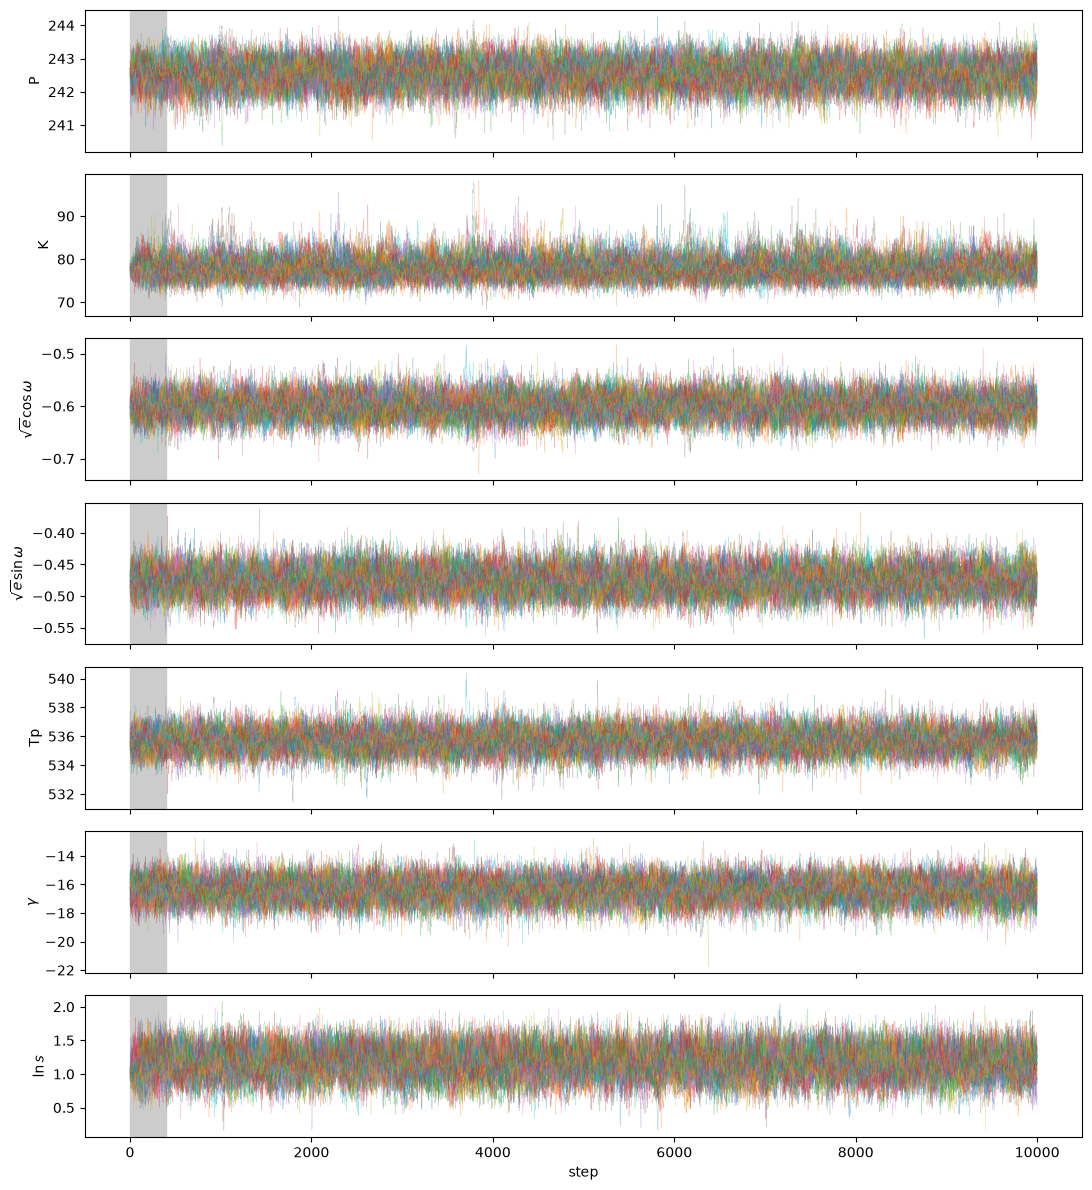

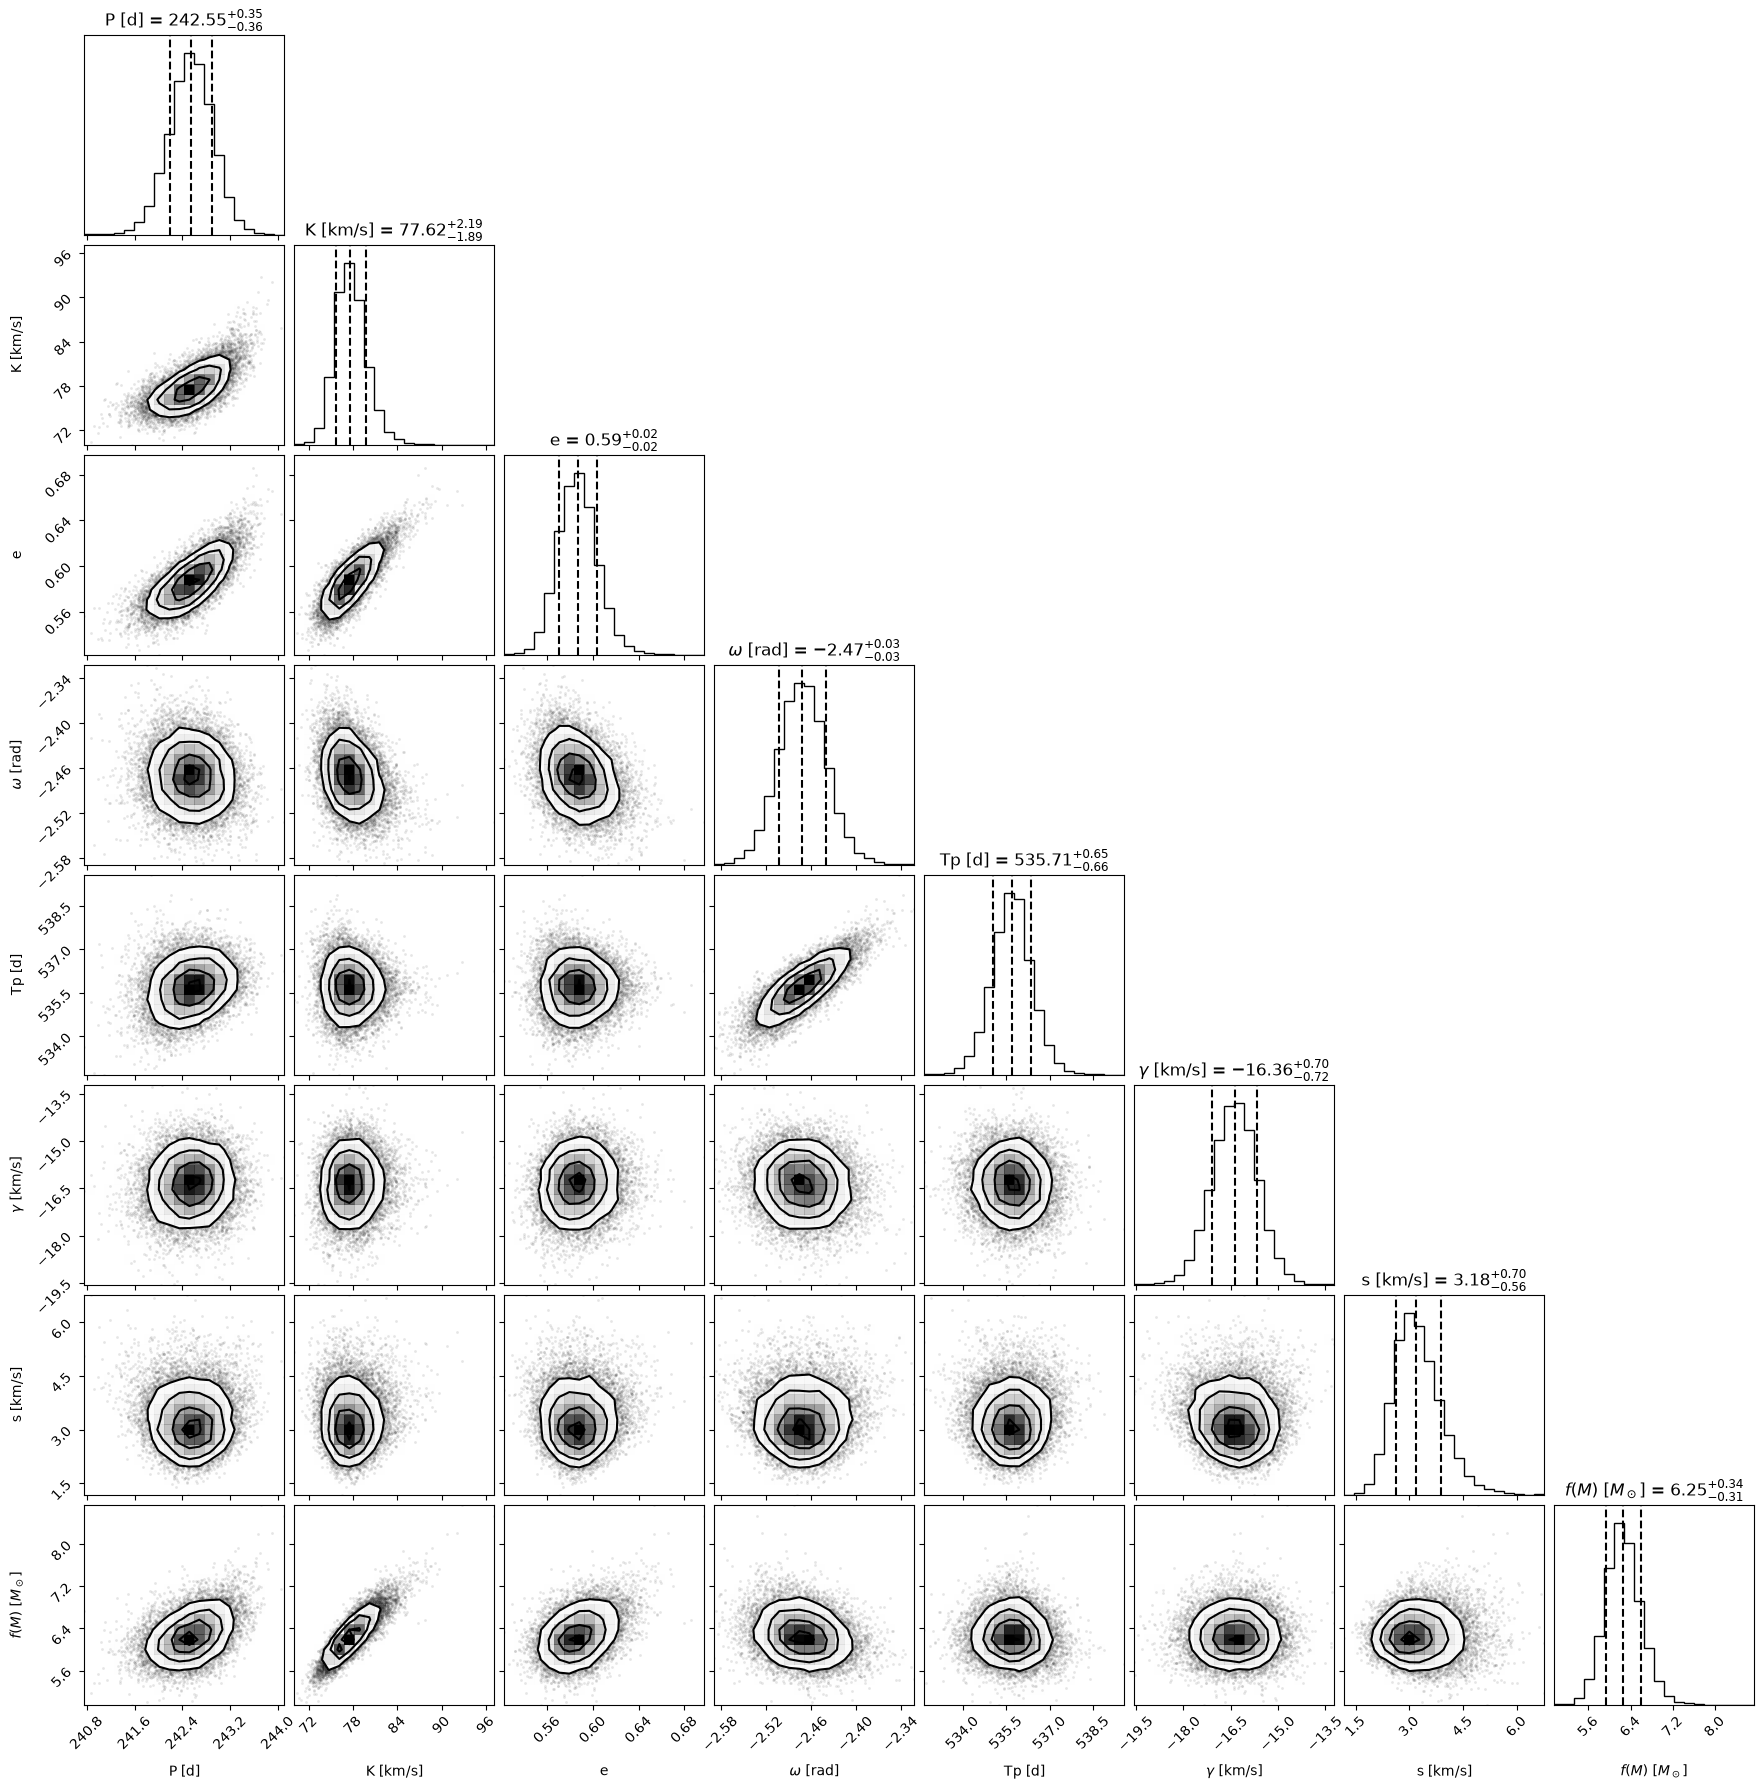

P      = 242.6 +0.35 / -0.36
K      = 77.62 +2.2 / -1.9
e      = 0.5866 +0.017 / -0.016
gamma  = -16.36 +0.7 / -0.72
s      = 3.184 +0.7 / -0.56
f(M)   = 6.252 +0.34 / -0.31

P = 242.6 ± 0.36 d, K = 77.62 ± 2 km/s, e = 0.5866 ± 0.017, gamma = -16.36 ± 0.71 km/s, s = 3.184 ± 0.63 km/s, f(M) = 6.252 ± 0.33 Msun
P(f(M) > 3 Msun) = 1.000


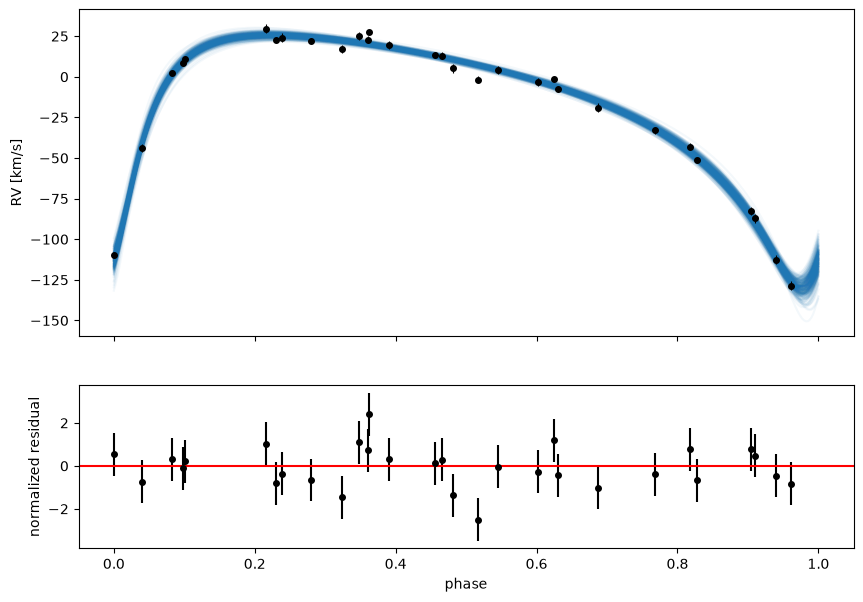

chi2 = 26.9 for 23 dof;  rms normalized residual = 0.94
without jitter (s=0) the same orbit gives chi2 = 116.3


In [8]:
# MLE per period 
def neg_ml(theta):
    if not np.isfinite(log_prior(theta)):
        return 1e10
    return -log_likelihood(theta)

K0 = 0.5 * (rv.max() - rv.min())
g0 = np.average(rv, weights=1 / sig**2)
nm = dict(maxiter=6000, maxfev=6000, xatol=1e-6, fatol=1e-6, adaptive=True)

def fit_from(P0, w0, phase0, e0=0.3):
    x0 = [P0, K0, np.sqrt(e0) * np.cos(w0), np.sqrt(e0) * np.sin(w0), t_mid + phase0 * P0, g0, 0.0]
    r = minimize(neg_ml, x0, method='Nelder-Mead', options=nm)
    return minimize(neg_ml, r.x, method='Nelder-Mead', options=nm)   # restart to polish

# the Part 1 peaks, plus 2x and 0.5x the best one to guard against a harmonic mix-up
starts = list(cands) + [2 * cands[0], 0.5 * cands[0]]
results = []                                   # (log L, x, starting P)
for P0 in starts:
    for w0 in np.arange(4) * np.pi / 2:
        for ph in (np.arange(4) + 0.5) / 4 - 0.5:
            r = fit_from(P0, w0, ph)
            if r.fun < 1e9:
                results.append((-r.fun, r.x, P0))
results.sort(key=lambda r: r[0], reverse=True)

best = results[0]
runner = next((r for r in results if abs(r[1][0] / best[1][0] - 1) > 0.02), None)  # best fit in a *different* period basin
print(f"best:      lnL = {best[0]:.2f}, P = {best[1][0]:.2f} d (started from {best[2]:.1f})")
if runner:
    print(f"runner-up: lnL = {runner[0]:.2f}, P = {runner[1][0]:.2f} d  ->  Delta lnL = {best[0]-runner[0]:.2f}")

# walker start
x0 = best[1].copy()
x0[6] = np.clip(x0[6], -5, 3)
x0[4] -= np.round((x0[4] - t_mid) / x0[0]) * x0[0]
Tp_lo, Tp_hi = x0[4] - x0[0] / 2, x0[4] + x0[0] / 2

nwalk, nsteps, ndim = 64, 10_000, 7
rng = np.random.default_rng(0)
scale = np.array([0.1, 0.5, 0.01, 0.01, 0.5, 0.5, 0.05])
p0 = x0 + scale * rng.normal(size=(nwalk, ndim))
for i in range(nwalk):
    while not np.isfinite(log_posterior(p0[i], Tp_lo, Tp_hi)):
        p0[i] = x0 + scale * rng.normal(size=ndim)

# this takes SO long 
sampler = emcee.EnsembleSampler(nwalk, ndim, log_posterior, args=(Tp_lo, Tp_hi))
sampler.run_mcmc(p0, nsteps, progress=False)

tau = sampler.get_autocorr_time(quiet=True)
print("tau per parameter:", np.round(tau).astype(int), f"| chain length / tau_max = {nsteps / tau.max():.0f} (want > 50)")
burn, thin = int(5 * tau.max()), max(1, int(tau.max() / 2))
print(f"burn-in {burn}, thin {thin}")
flat = sampler.get_chain(discard=burn, thin=thin, flat=True)
flat_lp = sampler.get_log_prob(discard=burn, thin=thin, flat=True)
print(flat.shape[0], "thinned samples; mean acceptance", sampler.acceptance_fraction.mean().round(2))

# plots
names = ['P', 'K', r'$\sqrt{e}\cos\omega$', r'$\sqrt{e}\sin\omega$', 'Tp', r'$\gamma$', r'$\ln s$']
chain = sampler.get_chain()
fig, axs = plt.subplots(ndim, 1, figsize=(11, 12), sharex=True)
for i, ax in enumerate(axs):
    ax.plot(chain[:, :, i], lw=0.3, alpha=0.4)
    ax.axvspan(0, burn, color='0.8'); ax.set_ylabel(names[i])
axs[-1].set_xlabel('step'); plt.tight_layout(); plt.show()

P_s, K_s, e_s, w_s, Tp_s, g_s, s_s = unpack(flat.T)
w_c = np.arctan2(np.mean(np.sin(w_s)), np.mean(np.cos(w_s)))
w_s = (w_s - w_c + np.pi) % (2 * np.pi) - np.pi + w_c
fM_s = mass_function(P_s, K_s, e_s)

phys = np.c_[P_s, K_s, e_s, w_s, Tp_s, g_s, s_s, fM_s]
labels = ['P [d]', 'K [km/s]', 'e', r'$\omega$ [rad]', 'Tp [d]', r'$\gamma$ [km/s]', 's [km/s]', r'$f(M)$ [$M_\odot$]']
corner.corner(phys, labels=labels, quantiles=[0.16, 0.5, 0.84], show_titles=True)
plt.show()

def q(x):
    lo, md, hi = np.percentile(x, [16, 50, 84]); return md, hi - md, md - lo
for nm_, x in zip(['P', 'K', 'e', 'gamma', 's', 'f(M)'], [P_s, K_s, e_s, g_s, s_s, fM_s]):
    m, up, dn = q(x); print(f"{nm_:6s} = {m:.4g} +{up:.2g} / -{dn:.2g}")

def fmt(x):
    m, up, dn = q(x); return f"{m:.4g} ± {0.5 * (up + dn):.2g}"
print(f"\nP = {fmt(P_s)} d, K = {fmt(K_s)} km/s, e = {fmt(e_s)}, gamma = {fmt(g_s)} km/s, s = {fmt(s_s)} km/s, f(M) = {fmt(fM_s)} Msun")
print(f"P(f(M) > 3 Msun) = {np.mean(fM_s > 3):.3f}")

P_med, Tp_med = np.median(P_s), np.median(Tp_s)
phi = np.linspace(0, 1, 400)
tt = Tp_med + phi * P_med
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
for j in rng.integers(0, flat.shape[0], 300):
    a1.plot(phi, kepler_rv(tt, P_s[j], K_s[j], e_s[j], unpack(flat[j])[3], Tp_s[j], g_s[j]), color='C0', alpha=0.05)
phase = ((t - Tp_med) / P_med) % 1
a1.errorbar(phase, rv, sig, fmt='o', color='k', ms=4, elinewidth=0.8)
a1.set_ylabel('RV [km/s]')

imap = np.argmax(flat_lp)
Pm, Km, em, wm, Tm, gm, sm = unpack(flat[imap])
resid = (rv - kepler_rv(t, Pm, Km, em, wm, Tm, gm)) / np.sqrt(sig**2 + sm**2)
a2.errorbar(phase, resid, 1, fmt='o', color='k', ms=4); a2.axhline(0, color='r')
a2.set_xlabel('phase'); a2.set_ylabel('normalized residual'); plt.show()
print(f"chi2 = {np.sum(resid**2):.1f} for {t.size - 7} dof;  rms normalized residual = {resid.std():.2f}")
print(f"without jitter (s=0) the same orbit gives chi2 = {np.sum(((rv - kepler_rv(t, Pm, Km, em, wm, Tm, gm))/sig)**2):.1f}")

**FINAL ANSWER:** $P = $ 242.6 $\pm$ 0.4 d, $K = $ 77.6 $\pm$ 2.0 km/s, $e = $ 0.587 $\pm$ 0.017 , $\gamma = $ -16.4 $\pm$ 0.7 km/s, $s = $ 3.2 $\pm$ 0.6 km/s, $f(M) = $ 6.25 $\pm$ 0.33 $M_\odot$

**Black-hole candidate?** 
Yes, this is a black hole candidate since the lower limit f(M) exceeds 3Msun in all posterior samples. 

## Part 3: The referee report (35%)

The file `ai_solution.ipynb` in this directory is a complete, tidy, confident MCMC analysis of this exact
problem, produced by an AI assistant. It runs top to bottom without errors, the corner plot is handsome, and
the prose is fluent. It is also wrong, in at least **three** distinct, substantive ways (cosmetic nitpicks and
style don't count; "it used 24 walkers and I used 32" is not a finding).

Write a referee report:

1. **Identify** at least three substantive statistical errors.
2. **Demonstrate** each one quantitatively on *your* dataset: show, with a number or a plot, what the error
   does to the inference. For a sampler, "demonstrate" usually means running it the wrong way and the right
   way and comparing. A demonstration can come out negative: if an error turns out not to move *your*
   numbers, showing that, and saying what it would take for it to bite, is a valid finding.
3. **State** the correct treatment (you built it in Part 2).

Third time you have done this. You should be finding these in minutes now.


In [15]:
freq_ai = np.linspace(1/600., 1/20., 20000)
P_peak = 1. / freq_ai[np.argmax(LombScargle(t, rv, sig).power(freq_ai))]
print(f"AI's LS peak: {P_peak:.1f} d  vs  my posterior P = {np.median(P_s):.2f} d")

def kepler_rv_fast(t, P, K, e, omega, Tp, gamma):
    M = 2. * np.pi * ((t - Tp) / P % 1.0)
    E = M.copy()
    for _ in range(30):
        dE = (E - e * np.sin(E) - M) / (1. - e * np.cos(E))
        E = E - dE
        if np.max(np.abs(dE)) < 1e-10:
            break
    nu = 2. * np.arctan2(np.sqrt(1. + e) * np.sin(E / 2.), np.sqrt(1. - e) * np.cos(E / 2.))
    return gamma + K * (np.cos(nu + omega) + e * np.cos(omega))

def log_likelihood(theta):
    P, K, e, w, Tp, gamma, s = unpack(theta)
    model = kepler_rv_fast(t, P, K, e, w, Tp, gamma)
    var = sig**2 + s**2
    return -0.5 * np.sum((rv - model)**2 / var + np.log(2 * np.pi * var))

def ai_logpost(theta, P_prior, s, walls, tt):
    P, K, e, w, Tp, g = theta
    if not (2 < P < 2000 and 0 < K < 200 and 0 <= e < 0.95 and -200 < g < 200):
        return -np.inf
    if walls and not (0 <= w < 2*np.pi and 0 <= Tp < P): 
        return -np.inf
    lp = -np.log(P) if P_prior is None else -0.5 * ((P - P_prior[0]) / P_prior[1])**2
    model = kepler_rv_fast(tt, P, K, e, w, Tp, g)
    return lp - 0.5 * np.sum((rv - model)**2 / (sig**2 + s**2)) 

def run(logp, start, args, scale, nwalk=48, nsteps=6000, seed=0):
    np.random.seed(seed)
    start, scale = np.asarray(start, float), np.asarray(scale, float)
    p0 = start + scale * np.random.normal(size=(nwalk, start.size))
    for i in range(nwalk):
        while not np.isfinite(logp(p0[i], *args)):
            p0[i] = start + scale * np.random.normal(size=start.size)
    smp = emcee.EnsembleSampler(nwalk, start.size, logp, args=args)
    smp.run_mcmc(p0, nsteps, progress=False)
    tau = smp.get_autocorr_time(quiet=True)
    flat6 = smp.get_chain(discard=int(5*tau.max()), thin=max(1, int(tau.max()/2)), flat=True)
    print(f"  tau_max = {tau.max():.0f}, N/tau = {nsteps/tau.max():.0f}, acceptance = {smp.acceptance_fraction.mean():.2f}")
    return flat6

# my Part 2 solution as the common start and the "right" reference
Pm, Km, em, gm, sm = np.median(P_s), np.median(K_s), np.median(e_s), np.median(g_s), np.median(s_s)
wm, Tm = np.median(w_s) % (2*np.pi), np.median(Tp_s) % Pm
st6, sc6 = [Pm, Km, em, wm, Tm, gm], [0.1, 0.5, 0.01, 0.02, 0.5, 0.5]
ref6 = np.c_[P_s, K_s, e_s, w_s, Tp_s, g_s]

def table(f6):
    cols = dict(P=f6[:, 0], K=f6[:, 1], e=f6[:, 2], gamma=f6[:, 5], fM=mass_function(f6[:, 0], f6[:, 1], f6[:, 2]))
    return {k: (np.median(v), 0.5 * (np.percentile(v, 84) - np.percentile(v, 16))) for k, v in cols.items()}

def compare(label, f6):
    a, b = table(f6), table(ref6)
    print(label)
    for k in a:
        print(f"  {k:5s} wrong {a[k][0]:9.4g} ± {a[k][1]:.2g} | right {b[k][0]:9.4g} ± {b[k][1]:.2g}"
              f" | shift {(a[k][0]-b[k][0])/b[k][1]:+5.1f} sigma_right | width ratio {a[k][1]/b[k][1]:.2f}")

AI's LS peak: 234.7 d  vs  my posterior P = 242.55 d


In [16]:
# Part 3: your work here

# 1. no jitter (s = 0)
flat_nj = run(ai_logpost, st6, args=(None, 0.0, False, t), scale=sc6)
compare("no-jitter vs. jitter posterior", flat_nj)

med_nj = np.median(flat_nj, axis=0)
chi2_nj = np.sum(((rv - kepler_rv_fast(t, *med_nj)) / sig)**2)
print(f"chi2 of the median orbit with sigma only: {chi2_nj:.1f} for {t.size-6} dof "
      f"(reduced {chi2_nj/(t.size-6):.1f}); Part 2 with jitter: chi2 = 27.5 for 23 dof")

# 2. periodogram-centred Gaussian prior on P 
flat_pp = run(ai_logpost, st6, args=((P_peak, 0.5), sm, False, t), scale=sc6, nsteps=10000)
compare("AI period prior vs. log-uniform prior", flat_pp)

def chi2_at(f6, s):
    m = np.median(f6, axis=0)
    return np.sum((rv - kepler_rv_fast(t, *m))**2 / (sig**2 + s**2))
print(f"chi2 of the median orbit (s = {sm:.2f}): AI prior {chi2_at(flat_pp, sm):.1f} vs correct {chi2_at(ref6, sm):.1f}")

# 3. AI's sampler settings (24 walkers, 1500 steps, burn 100, 1e-3 ball)
hw = lambda v: 0.5 * (np.percentile(v, 84) - np.percentile(v, 16))
meds, hws = [], []
for sd in range(5):
    np.random.seed(sd)
    p0 = x0 + 1e-3 * np.random.normal(size=(24, 7))
    for i in range(24):
        while not np.isfinite(log_posterior(p0[i], Tp_lo, Tp_hi)):
            p0[i] = x0 + 1e-3 * np.random.normal(size=7)
    s_ = emcee.EnsembleSampler(24, 7, log_posterior, args=(Tp_lo, Tp_hi))
    s_.run_mcmc(p0, 1500, progress=False)
    tau_ = s_.get_autocorr_time(tol=0)
    K_ = s_.get_chain(discard=100, flat=True)[:, 1]
    meds.append(np.median(K_)); hws.append(hw(K_))
    print(f"  seed {sd}: acceptance {s_.acceptance_fraction.mean():.2f} (looks healthy), "
          f"tau_max {tau_.max():.0f}, N/tau {1500/tau_.max():.0f} (need >50), K = {meds[-1]:.2f} ± {hws[-1]:.2f}")
print(f"seed-to-seed scatter in the median K: {np.std(meds):.2f} km/s = {np.std(meds)/hw(K_s):.2f} x the correct sigma_K")
print(f"reported sigma_K ranges {min(hws):.2f}-{max(hws):.2f}; long-run (Part 2) sigma_K = {hw(K_s):.2f}")

  tau_max = 63, N/tau = 95, acceptance = 0.51
no-jitter vs. jitter posterior
  P     wrong     242.4 ± 0.18 | right     242.6 ± 0.36 | shift  -0.4 sigma_right | width ratio 0.50
  K     wrong     77.16 ± 1 | right     77.62 ± 2 | shift  -0.2 sigma_right | width ratio 0.49
  e     wrong    0.5749 ± 0.0077 | right    0.5866 ± 0.017 | shift  -0.7 sigma_right | width ratio 0.46
  gamma wrong     -15.7 ± 0.33 | right    -16.36 ± 0.71 | shift  +0.9 sigma_right | width ratio 0.47
  fM    wrong      6.32 ± 0.18 | right     6.252 ± 0.33 | shift  +0.2 sigma_right | width ratio 0.54
chi2 of the median orbit with sigma only: 107.9 for 24 dof (reduced 4.5); Part 2 with jitter: chi2 = 27.5 for 23 dof
  tau_max = 76, N/tau = 131, acceptance = 0.51
AI period prior vs. log-uniform prior
  P     wrong     239.7 ± 0.3 | right     242.6 ± 0.36 | shift  -8.1 sigma_right | width ratio 0.84
  K     wrong      72.9 ± 1.3 | right     77.62 ± 2 | shift  -2.3 sigma_right | width ratio 0.63
  e     wrong    0.535

**REFEREE REPORT:**

1. The AI-generated report does not include a jitter term. The sampler then treats the quoted errors as the whole error, which reduces the median orbit & error bars and wrongly attributes the bad fit to natural variance.
2. The prior of the data is calculated from the same data, which introduces double counting. This creates an overbiased, overconfident prior, which poorly feeds into f(M). It is also centered on a sinusoid-fit peak, which is biased for an eccentric orbit.
3. 24 walkers × 1500 steps with burn-in of 100 is far too short when τ ≈ 75. That is about 20τ against emcee’s 50τ rule, and the burn-in is about 1.3τ. This would raise a warning, but the AI-generated code suppresses it with the line `get_autocorr_time(tol=0)`. 

## Part 4: AI-use appendix and verification plan (10%)

1. **AI use**: which tools did you use, for what, what did they get wrong, and how did you catch it? Honesty
   is graded; "I didn't use any" is fine if true.
2. **Reflection (new from this lab on, two or three sentences)**: what did you use AI for in this lab, and
   what would have gone wrong in your answer if you had not checked its output? Name the specific thing, not
   "it could have made a mistake".
3. **Verification plan**: the checks you ran before trusting your Part 2 numbers, and what failure would have
   looked like for each. One you should seriously consider: generate a synthetic RV curve with parameters
   you choose, at *your* epochs, run your whole Part 2 pipeline on it, and see whether the 68% intervals
   contain what you put in. With seven parameters and one realisation, expect about five of seven inside
   their 68% intervals; one pull of 2.5σ is not a failure by itself. Failure looks systematic: the same
   parameter off in the same direction every time, or an interval that never contains the truth.


**AI-USE APPENDIX:**

As with previous labs, I used Claude's Sonnet 5.5 AI to generate some boilerplate code for this lab, particularly for the more mathematical helper functions (emcee walkers) where there were additional parameters and syntax I wanted to check on. Claude also contributed to make the graphs cleaner for the data they could show and helped format the fstring outputs to be more readable. In this lab, Claude also suggested the `tqdm` library to see the progress of my code in Part 2 after I expressed my concerns about kernel hanging. The responses and analysis I had for each question were my own. \
If you notice that this appendix is very similar to the ones submitted on the previous labs, that is a choice made intentionally, since AI was used the same way on both labs. 

**REFLECTION:**

I used AI to generate some boiler-plate code for the Lomb-Scargle fit in Part 1 and the emcee walkers in Part 2. The specific thing that would have gone wrong is the period calculation in part 1. The periodogram peak was 233.9 d, but the full Keplerian fit gives P = 242.6 $\pm$ 0.4 d because LS fits a sinusoid to an eccentric orbit. If I had fixed or tightly constrained P at the LS peak, it would have given me a an overconfident and incorrect period that would have ruined my final f(M) calculation. 

**VERIFICATION PLAN:**

I generated fake RV curves at my own epochs, with the true parameters set to my Part 2 medians and noise. I ran the full Part 2 pipeline on 8 noise realizations and computed each pull, (median − truth) / (68% half-width). Overall, 69% of the pulls fell inside 1 standard deviation, matching the 68% expected. The one flag is that K and f(M) have mean pulls of about +1.1 and +1.2 sigma, which suggests a possible small upward bias. With only 8 seeds that is suggestive rather than conclusive, and it would not change the black-hole conclusion.

In [10]:
# Verification Code: 

import copy

truth = dict(P=np.median(P_s), K=np.median(K_s), e=np.median(e_s), w=w_c,
             Tp=np.median(Tp_s), gamma=np.median(g_s), s=np.median(s_s))

def run_pipeline(rv_syn, nwalk=32, nsteps=6000):
    global rv, K0, g0
    rv_old, K0_old, g0_old = rv, K0, g0
    rv = rv_syn; K0 = 0.5 * (rv.max() - rv.min()); g0 = np.average(rv, weights=1 / sig**2)
    try:
        res = []
        for P0 in [truth['P']]: 
            for w0 in np.arange(3) * 2 * np.pi / 3:
                for ph in (-0.33, 0.0, 0.33):
                    r = fit_from(P0, w0, ph)
                    if r.fun < 1e9: res.append((-r.fun, r.x))
        x0 = max(res, key=lambda r: r[0])[1].copy()
        x0[6] = np.clip(x0[6], -5, 3)
        x0[4] -= np.round((x0[4] - t_mid) / x0[0]) * x0[0]
        lo, hi = x0[4] - x0[0] / 2, x0[4] + x0[0] / 2
        p0 = x0 + scale * rng.normal(size=(nwalk, ndim))
        for i in range(nwalk):
            while not np.isfinite(log_posterior(p0[i], lo, hi)): p0[i] = x0 + scale * rng.normal(size=ndim)
        smp = emcee.EnsembleSampler(nwalk, ndim, log_posterior, args=(lo, hi))
        smp.run_mcmc(p0, nsteps, progress=False)
        tau_ = smp.get_autocorr_time(quiet=True)
        fl = smp.get_chain(discard=int(5 * tau_.max()), thin=max(1, int(tau_.max() / 2)), flat=True)
        return fl, nsteps / tau_.max()
    finally:
        rv, K0, g0 = rv_old, K0_old, g0_old

wt = truth['w']
pulls = []
for seed in range(8):
    r_ = np.random.default_rng(1000 + seed)
    rv_syn = (kepler_rv(t, truth['P'], truth['K'], truth['e'], truth['w'], truth['Tp'], truth['gamma'])
              + r_.normal(0, np.sqrt(sig**2 + truth['s']**2)))
    fl, ratio = run_pipeline(rv_syn)
    Pf, Kf, ef, wf, Tf, gf, sf = unpack(fl.T)
    fMf = mass_function(Pf, Kf, ef)
    row = []
    for x, tv in [(Pf, truth['P']), (Kf, truth['K']), (ef, truth['e']), (gf, truth['gamma']),
                  (sf, truth['s']), (fMf, mass_function(truth['P'], truth['K'], truth['e']))]:
        lo_, md_, hi_ = np.percentile(x, [16, 50, 84])
        row.append((md_ - tv) / (0.5 * (hi_ - lo_)))
    pulls.append(row); print(seed, np.round(row, 2), f"N/tau = {ratio:.0f}")

pulls = np.array(pulls)
print("params: P, K, e, gamma, s, f(M)")
print("mean pull:", np.round(pulls.mean(0), 2), "  (want ~0)")
print("std pull: ", np.round(pulls.std(0), 2), "  (want ~1)")
print("fraction inside 1 sigma:", np.round((np.abs(pulls) < 1).mean(0), 2), "  (want ~0.68)")

0 [ 2.59  0.87  0.95  0.3  -0.38  0.72] N/tau = 78
1 [-0.89  0.29  0.08  0.66  0.03  0.32] N/tau = 72
2 [ 0.89  0.7   0.39 -1.37  0.32  0.79] N/tau = 73
3 [-0.86  1.06 -0.59 -1.25  0.13  1.92] N/tau = 73
4 [ 0.66  1.49  1.35  0.58 -1.29  1.29] N/tau = 75
5 [ 0.19  1.45  0.86 -0.98  0.2   1.6 ] N/tau = 72
6 [ 2.55  0.75  0.74  0.2  -0.17  0.67] N/tau = 71
7 [ 1.    1.86  0.54 -0.52 -0.17  2.39] N/tau = 79
params: P, K, e, gamma, s, f(M)
mean pull: [ 0.77  1.06  0.54 -0.3  -0.17  1.21]   (want ~0)
std pull:  [1.24 0.48 0.56 0.78 0.47 0.67]   (want ~1)
fraction inside 1 sigma: [0.62 0.5  0.88 0.75 0.88 0.5 ]   (want ~0.68)
